# Классификация музыкальных жанров: сравнение MLP, CNN и EfficientNet

**Фреймворк:** PyTorch  
**GPU:** указывается автоматически в следующей ячейке (CPU / CUDA / MPS)

Сравниваем три подхода к классификации спектрограмм GTZAN:
1. MLP из референса (`reference.ipynb`) — baseline 30,46%
2. Собственная свёрточная сеть (CNN)
3. Transfer learning на EfficientNet B0

In [25]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.metrics import confusion_matrix

torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    device = torch.device('cuda')
    gpu_name = torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    device = torch.device('mps')
    gpu_name = 'Apple MPS'
else:
    device = torch.device('cpu')
    gpu_name = None

print(f'Фреймворк: PyTorch {torch.__version__}')
print(f'Устройство: {device}' + (f' ({gpu_name})' if gpu_name else ''))

Фреймворк: PyTorch 2.12.0
Устройство: mps (Apple MPS)


## Загрузка датасета

Датасет скачивается в `./data/` через Kaggle API. Токен — в `.env` (см. `.env.example`) или `just download-dataset`.

In [ ]:
from download_dataset import download_dataset

dataset_root = download_dataset()
print('Путь к датасету:', dataset_root)

Kaggle credentials set.
Path to dataset files: /Users/karimovdmitry/projects/mephi/adv-ml/data


In [26]:
possible_paths = [
    Path('data'),
]

dataset_path = next((p for p in possible_paths if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError('Датасет не найден. Выполните: just download-dataset')

data_path = dataset_path / 'Data' if (dataset_path / 'Data').exists() else dataset_path
image_path = data_path / 'images_original'

class_names = sorted(d.name for d in image_path.iterdir() if d.is_dir())
num_classes = len(class_names)
print(f'Датасет: {dataset_path}')
print(f'Жанры ({num_classes}): {class_names}')

Датасет: data
Жанры (10): ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


## Подготовка данных

Собираем пути к изображениям и метки. Разбиение 70/15/15 — как в `reference.ipynb` (seed=42).

In [12]:
image_paths = []
image_labels = []

for class_idx, class_name in enumerate(class_names):
    class_dir = image_path / class_name
    for img_path in sorted(class_dir.glob('*.png')):
        image_paths.append(str(img_path))
        image_labels.append(class_idx)

image_labels = np.array(image_labels)
print(f'Всего изображений: {len(image_paths)}')


def split_indices(n_samples, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15, seed=42):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(n_samples)
    train_end = int(train_ratio * n_samples)
    val_end = train_end + int(val_ratio * n_samples)
    return indices[:train_end], indices[train_end:val_end], indices[val_end:]


train_idx, val_idx, test_idx = split_indices(len(image_paths))
print(f'Train: {len(train_idx)}, Val: {len(val_idx)}, Test: {len(test_idx)}')

Всего изображений: 999
Train: 699, Val: 149, Test: 151


In [13]:
class SpectrogramDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label

In [14]:
MODELS_DIR = Path('models')
MODELS_DIR.mkdir(exist_ok=True)

def evaluate(model, loader, device):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            preds = outputs.argmax(dim=1)
            total += y.size(0)
            correct += (preds == y).sum().item()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())
    return correct / total, all_preds, all_labels


def train_model(model, train_loader, val_loader, *, epochs, optimizer, device, model_name):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    best_val_acc = 0.0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                outputs = model(x)
                loss = criterion(outputs, y)
                val_loss += loss.item()
                preds = outputs.argmax(dim=1)
                total += y.size(0)
                correct += (preds == y).sum().item()
        val_loss /= len(val_loader)
        val_acc = correct / total

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), MODELS_DIR / f'best_{model_name}.pth')

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(
                f'{model_name} | Эпоха {epoch + 1}/{epochs} | '
                f'train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f}'
            )

    model.load_state_dict(torch.load(MODELS_DIR / f'best_{model_name}.pth', map_location=device, weights_only=True))
    return model, history, best_val_acc


## Задание 1. Свёрточная сеть

Архитектура: Conv(32→64→128) + ReLU + MaxPool → FC(256) + ReLU + Dropout(0.3) → 10 классов.  
Вход 128×128, оптимизатор AdamW, 50 эпох.

In [15]:
class GenreCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # 128x128 -> после 3 MaxPool: 16x16
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


cnn_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

cnn_dataset = SpectrogramDataset(image_paths, image_labels, transform=cnn_transform)
batch_size = 32
# num_workers=0 обязателен в Jupyter: воркеры не видят классы, объявленные в ноутбуке
num_workers = 0

cnn_train_loader = DataLoader(Subset(cnn_dataset, train_idx), batch_size=batch_size, shuffle=True, num_workers=num_workers)
cnn_val_loader = DataLoader(Subset(cnn_dataset, val_idx), batch_size=batch_size, shuffle=False, num_workers=num_workers)
cnn_test_loader = DataLoader(Subset(cnn_dataset, test_idx), batch_size=batch_size, shuffle=False, num_workers=num_workers)

cnn_model = GenreCNN(num_classes=num_classes)
print(cnn_model)
print(f'Параметров: {sum(p.numel() for p in cnn_model.parameters()):,}')

GenreCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Параметров: 8,484,682


In [16]:
cnn_optimizer = optim.AdamW(cnn_model.parameters(), lr=1e-3, weight_decay=0.01)
cnn_model, cnn_history, cnn_best_val = train_model(
    cnn_model,
    cnn_train_loader,
    cnn_val_loader,
    epochs=50,
    optimizer=cnn_optimizer,
    device=device,
    model_name='cnn',
)
print(f'Лучшая val accuracy (CNN): {cnn_best_val:.4f}')

cnn | Эпоха 1/50 | train_loss=2.3263 | val_loss=2.3003 | val_acc=0.0872
cnn | Эпоха 10/50 | train_loss=1.3459 | val_loss=1.5579 | val_acc=0.4564
cnn | Эпоха 20/50 | train_loss=0.5670 | val_loss=1.6888 | val_acc=0.5034
cnn | Эпоха 30/50 | train_loss=0.1911 | val_loss=2.1175 | val_acc=0.5436
cnn | Эпоха 40/50 | train_loss=0.0856 | val_loss=2.5480 | val_acc=0.5034
cnn | Эпоха 50/50 | train_loss=0.0500 | val_loss=3.0517 | val_acc=0.5369
Лучшая val accuracy (CNN): 0.5503


In [17]:
cnn_test_acc, cnn_preds, cnn_labels = evaluate(cnn_model, cnn_test_loader, device)
print(f'CNN test accuracy: {cnn_test_acc:.4f} ({cnn_test_acc * 100:.2f}%)')

CNN test accuracy: 0.5828 (58.28%)


## Задание 2. Transfer Learning — EfficientNet B0

Предобученные веса ImageNet, заморозка backbone, новый классификатор на 10 классов.  
Аугментация: RandomHorizontalFlip, RandomRotation. Вход 224×224, Adam, 30 эпох.

In [18]:
effnet_weights = EfficientNet_B0_Weights.IMAGENET1K_V1
effnet_preset = effnet_weights.transforms()
effnet_mean, effnet_std = effnet_preset.mean, effnet_preset.std

effnet_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=effnet_mean, std=effnet_std),
])

effnet_eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=effnet_mean, std=effnet_std),
])

effnet_train_dataset = SpectrogramDataset(image_paths, image_labels, transform=effnet_train_transform)
effnet_eval_dataset = SpectrogramDataset(image_paths, image_labels, transform=effnet_eval_transform)

effnet_train_loader = DataLoader(Subset(effnet_train_dataset, train_idx), batch_size=16, shuffle=True, num_workers=num_workers)
effnet_val_loader = DataLoader(Subset(effnet_eval_dataset, val_idx), batch_size=16, shuffle=False, num_workers=num_workers)
effnet_test_loader = DataLoader(Subset(effnet_eval_dataset, test_idx), batch_size=16, shuffle=False, num_workers=num_workers)

effnet_model = efficientnet_b0(weights=effnet_weights)
for param in effnet_model.parameters():
    param.requires_grad = False

in_features = effnet_model.classifier[1].in_features
effnet_model.classifier[1] = nn.Linear(in_features, num_classes)

trainable = sum(p.numel() for p in effnet_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in effnet_model.parameters())
print(f'EfficientNet B0: обучаемых параметров {trainable:,} из {total:,}')

EfficientNet B0: обучаемых параметров 12,810 из 4,020,358


In [19]:
effnet_optimizer = optim.Adam(filter(lambda p: p.requires_grad, effnet_model.parameters()), lr=1e-3)
effnet_model, effnet_history, effnet_best_val = train_model(
    effnet_model,
    effnet_train_loader,
    effnet_val_loader,
    epochs=30,
    optimizer=effnet_optimizer,
    device=device,
    model_name='effnet',
)
print(f'Лучшая val accuracy (EfficientNet): {effnet_best_val:.4f}')

effnet | Эпоха 1/30 | train_loss=2.0770 | val_loss=2.0257 | val_acc=0.3960
effnet | Эпоха 10/30 | train_loss=1.2490 | val_loss=1.3783 | val_acc=0.5503
effnet | Эпоха 20/30 | train_loss=1.0622 | val_loss=1.2356 | val_acc=0.6107
effnet | Эпоха 30/30 | train_loss=1.0188 | val_loss=1.2537 | val_acc=0.6242
Лучшая val accuracy (EfficientNet): 0.6309


In [20]:
effnet_test_acc, effnet_preds, effnet_labels = evaluate(effnet_model, effnet_test_loader, device)
print(f'EfficientNet test accuracy: {effnet_test_acc:.4f} ({effnet_test_acc * 100:.2f}%)')

EfficientNet test accuracy: 0.6093 (60.93%)


## Задание 3. Сравнение результатов

In [21]:
mlp_baseline = 0.3046

results = pd.DataFrame({
    'Модель': [
        'MLP (reference.ipynb, спектрограммы 64×64)',
        'Свёрточная сеть (CNN)',
        'EfficientNet B0 (transfer learning)',
    ],
    'Точность': [
        f'{mlp_baseline * 100:.2f}%',
        f'{cnn_test_acc * 100:.2f}%',
        f'{effnet_test_acc * 100:.2f}%',
    ],
})
display(results)

,Модель,Точность
0,"MLP (reference.ipynb, спектрограммы 64×64)",30.46%
1,Свёрточная сеть (CNN),58.28%
2,EfficientNet B0 (transfer learning),60.93%


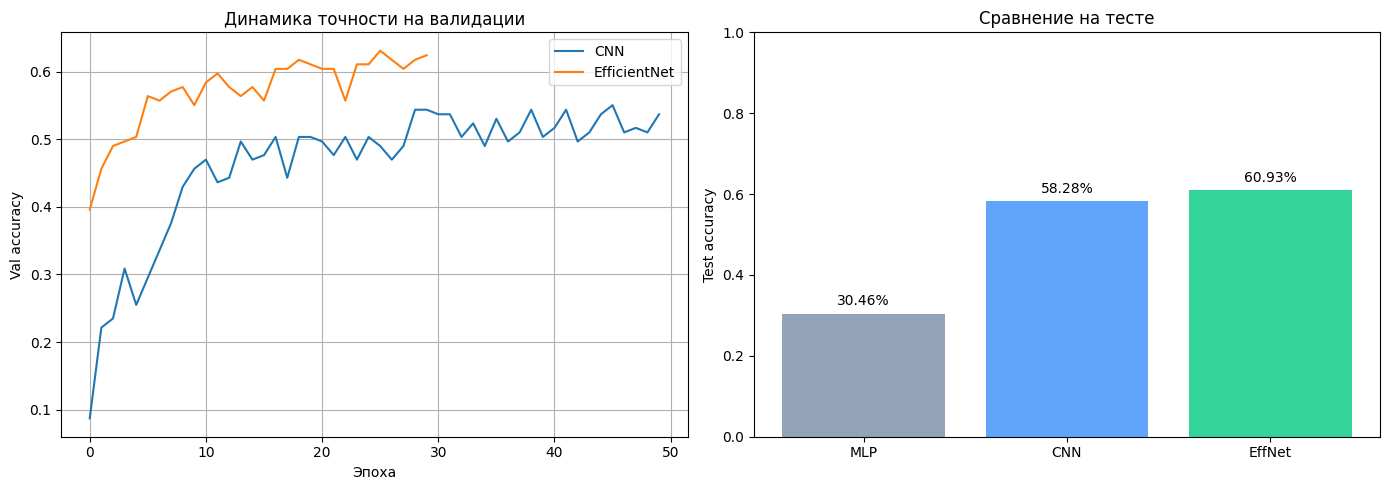

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(cnn_history['val_acc'], label='CNN')
axes[0].plot(effnet_history['val_acc'], label='EfficientNet')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Val accuracy')
axes[0].set_title('Динамика точности на валидации')
axes[0].legend()
axes[0].grid(True)

models = ['MLP', 'CNN', 'EffNet']
accs = [mlp_baseline, cnn_test_acc, effnet_test_acc]
bars = axes[1].bar(models, accs, color=['#94a3b8', '#60a5fa', '#34d399'])
axes[1].set_ylim(0, 1)
axes[1].set_ylabel('Test accuracy')
axes[1].set_title('Сравнение на тесте')
for bar, acc in zip(bars, accs):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02, f'{acc:.2%}', ha='center')

plt.tight_layout()
plt.show()

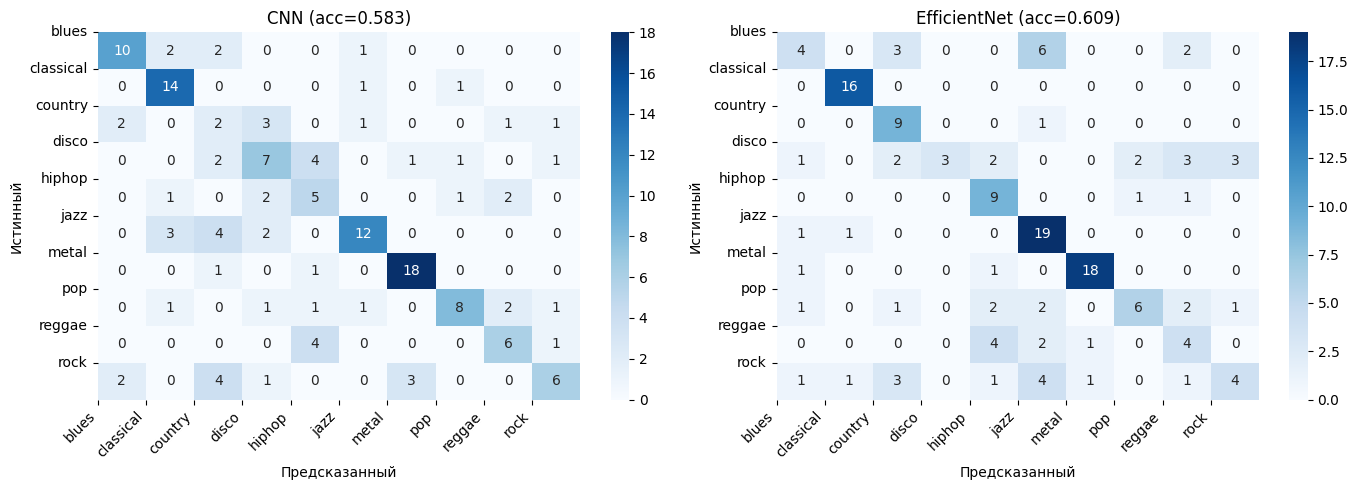

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, preds, labels, title in [
    (axes[0], cnn_preds, cnn_labels, f'CNN (acc={cnn_test_acc:.3f})'),
    (axes[1], effnet_preds, effnet_labels, f'EfficientNet (acc={effnet_test_acc:.3f})'),
]:
    cm = confusion_matrix(labels, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Предсказанный')
    ax.set_ylabel('Истинный')
    ax.set_xticks(range(num_classes))
    ax.set_yticks(range(num_classes))
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_yticklabels(class_names, rotation=0)

plt.tight_layout()
plt.show()

Выводы

1. MLP (30.46%) — худший результат, ожидаемо, сеть разворачивает спектрограмму в вектор и не использует пространственную структуру и не видит локальные зависимости пикселей.

2. CNN (58.28%) — существенный рост относительно MLP. CNN извлекает локальные паттерны на спектрограмме.

3. EfficientNet B0 (60.93%) — лучший результат. Предобучение на ImageNet даёт богатые фильтры низкого уровня, аугментация снижает переобучение на маленьком датасете (1000 изображений).

Наилучшая модель: EfficientNet B0. Качество растёт по цепочке MLP → CNN → EfficientNet: от игнорирования структуры изображения к явному извлечению локальных признаков и transfer learning.